# 18 · Closed-loop decoder selection as a contextual bandit

A closed-loop fUS-BMI has two knobs that change what the user experiences each trial:
which decoder produces the cursor command, and how strongly feedback is presented
(gain). This notebook treats the pair as an *action* and picks it trial by trial with a
contextual bandit (LinUCB, linear Thompson sampling), on simulated data shaped like the
public Caltech fUS-BMI dataset (Griggs et al., Nat. Neurosci. 2024).

**Everything here is simulated.** The `caltech_like` recordings reuse the repo simulator with
the dataset's frame rate, plane geometry and trial states; no Caltech file was read. Accuracy
and regret numbers describe this simulator, not the real data.

## Conceptual model

```
train sessions ──► fit PCA+LDA arms ──────────────┐
                                                   ▼
test sessions ──► ReplayEnv      (recorded trials; every arm scored on every trial)
train sessions ─► FittedSimulator ─► FittedSimEnv (generated trials; gain scales the signal)

per trial t:  context x_t ─► policy ─► action a_t = (arm, gain) ─► reward r_t = 1[decoded dir = true dir]
              (mask removes unsafe actions BEFORE the policy scores them)
```

* **Counterfactual rewards.** A decoder's output does not change the recorded brain data, so on
  a recorded trial the reward of *every* arm is known. That gives exact per-trial regret
  (`oracle - reward`) and a best-fixed-arm-in-hindsight baseline. This does not hold on a live
  system, where the user adapts to the decoder.
* **Context.** `[1, recent success rate, trial index / n, previous decoder confidence]`.
* **Safety is a mask, not a penalty.** Actions with gain above `max_gain` or from an
  unvalidated decoder are removed before selection. A reward penalty could be out-weighed by
  reward and would still allow the unsafe action during exploration.
* **Gain in each env.** In `ReplayEnv` gain has no effect (recorded under one feedback), so
  gain variants of an arm tie. In `FittedSimEnv` gain changes the evoked amplitude through an
  *assumed* inverted-U rule (`gain_amplitude`); it is not an estimate from data.
* **Fitted simulator.** Per-direction mean response and residual noise are estimated on train
  sessions only. Its noise is AR(1) with one coefficient and no between-session variability, so
  it is easier than the replay data; read it as a mechanism demo.

In [1]:
import os, sys, tempfile, time, warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("ML_LOG_LEVEL", "WARNING")   # keep structlog output out of the notebook
os.environ.setdefault("RAY_DEDUP_LOGS", "1")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
T7 = "/Volumes/T7/ml-platform-data/tmp"
if os.path.isdir("/Volumes/T7/ml-platform-data"):
    os.makedirs(T7, exist_ok=True); os.environ['TMPDIR'] = T7; tempfile.tempdir = T7  # keep scratch off the internal disk
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.6), "axes.grid": True,
                     "grid.alpha": 0.3})

# Every artifact this notebook creates lives in a fresh temp dir -- never in the repo's
# data/, artifacts/ or mlflow.db.
WORK = Path(tempfile.mkdtemp(prefix="nb18_"))
T0 = time.perf_counter()
print("workspace:", WORK)

workspace: /Volumes/T7/ml-platform-data/tmp/nb18_2iurdml2


In [2]:
from ml_platform.workloads.fusi_realtime import bandit as B
from ml_platform.workloads.fusi_realtime import caltech_like as CL
from ml_platform.workloads.fusi_realtime import realdata as RD
from ml_platform.workloads.fusi_realtime import replay as RP
from ml_platform.workloads.fusi_realtime.config import BanditConfig, CaltechLikeConfig

cc = CaltechLikeConfig()
bc = BanditConfig()
SEEDS = (0, 1, 2)
N_TRIALS = 300
print("T7 scratch:", WORK.parent)

T7 scratch: /Volumes/T7/ml-platform-data/tmp


## 1 · The `caltech_like` calibration and its assumptions

Each row states whether a value is confirmed from the dataset description / authors' code or
is an assumption of this simulator. No extracted `.mat` was available.

In [3]:
rows = [
    ("frame rate", f"{cc.frame_rate_hz} Hz", "confirmed (dataset description)"),
    ("imaging geometry", "2-D plane, y = 1", "confirmed (dop is (depth, lateral, time))"),
    ("plane size", f"{cc.n_lateral} x {cc.n_depth} voxels", "assumption"),
    ("state names", "trialstart ... iti (9)", "confirmed (rt_fUS_BMI behavior fields)"),
    ("state durations (s)", f"fix {cc.fixation_s}, cue {cc.cue_s}, memory {cc.memory_s}, acquire {cc.target_acquire_s}, hold {cc.target_hold_s}, reward {cc.reward_s}, iti {cc.iti_s}", "assumption"),
    ("directions", f"{cc.n_directions} (2 as variant)", "paper: 8 targets"),
    ("hemodynamic lag", f"peak {cc.hrf_peak_s} s", "Norman et al. 2021 (1-2 s)"),
    ("signal gain / speckle looks", f"{cc.signal_gain} / {cc.speckle_looks:g}", "assumption"),
    ("lapse rate", f"{cc.lapse_rate}", "assumption"),
]
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(rows, columns=["quantity", "value", "source"])

,quantity,value,source
0,frame rate,2.0 Hz,confirmed (dataset description)
1,imaging geometry,"2-D plane, y = 1","confirmed (dop is (depth, lateral, time))"
2,plane size,128 x 96 voxels,assumption
3,state names,trialstart ... iti (9),confirmed (rt_fUS_BMI behavior fields)
4,state durations (s),"fix 1.0, cue 1.0, memory 2.0, acquire 1.0, hold 1.0, reward 0.5, iti 2.0",assumption
5,directions,8 (2 as variant),paper: 8 targets
6,hemodynamic lag,peak 1.5 s,Norman et al. 2021 (1-2 s)
7,signal gain / speckle looks,0.2 / 16,assumption
8,lapse rate,0.05,assumption


In [4]:
t0 = time.perf_counter()
N_SESS, TRIALS_PER_SESS, N_TRAIN = 7, 60, 4
recs = [CL.simulate_caltech_like_recording(cc, s, TRIALS_PER_SESS) for s in range(N_SESS)]
train, test = recs[:N_TRAIN], recs[N_TRAIN:]
r0 = recs[0]
print(f"simulated {N_SESS} sessions in {time.perf_counter() - t0:.1f}s; doppler {r0.doppler.shape}, "
      f"fs {r0.fs_hz} Hz, {len(r0.events)} trials, directions {sorted(set(r0.events.direction))}")

# round trip through the .mat writer and the real-data loader (small plane to keep it tiny)
tiny = CaltechLikeConfig(n_lateral=16, n_depth=16)
mat = CL.write_mat(CL.simulate_caltech_like_recording(tiny, 0, 8), WORK / "rt_fUS_data_S1_R1.mat")
back = RD.load_caltech_session(mat)
print("loader round trip:", back.doppler.shape, back.fs_hz, len(back.events), "trials")

simulated 7 sessions in 1.7s; doppler (1029, 128, 1, 96), fs 2.0 Hz, 60 trials, directions [0, 1, 2, 3, 4, 5, 6, 7]
loader round trip: (145, 16, 1, 16) 2.0 8 trials


## 2 · Decoder arms fitted on train sessions only

Four validated PCA+LDA arms differ in the causal averaging window (`n_frames`), PCA size and
shrinkage; `weak_k2` keeps two components and acts as a deliberately poor arm. A fifth arm,
`candidate_unvalidated`, is configured but not validated, so the mask removes it. Test sessions
are never seen by the arms or the fitted simulator.

In [5]:
t0 = time.perf_counter()
arms = B.fit_arms(train, bc, n_classes=cc.n_directions)
bank = B.build_trial_bank(test, bc)
sim = RP.FittedSimulator().fit(train)
assert not set(sim.seen) & {r.name for r in test}
print(f"fitted in {time.perf_counter() - t0:.1f}s on {sim.seen}; held-out trials: {len(bank.directions)}")

replay_env = B.ReplayEnv(arms, bank, bc)
sim_env = B.FittedSimEnv(arms, sim, bc)
acc = {n: float((B._decide(a, bank.feats[a.cfg.n_frames])[0] == bank.directions).mean())
       for n, a in arms.items()}
print("held-out accuracy per arm (chance 0.125):")
print(pd.Series(acc).round(3).to_string())

fitted in 14.5s on ['caltech_like_S0', 'caltech_like_S1', 'caltech_like_S2', 'caltech_like_S3']; held-out trials: 180
held-out accuracy per arm (chance 0.125):
lda_w1_k32               0.411
lda_w3_k32               0.506
lda_w5_k16               0.422
weak_k2                  0.117
candidate_unvalidated    0.506


## 3 · Regret curves

Cumulative regret = sum of (best allowed action's reward on that trial - reward obtained). The
oracle picks the best arm per trial with hindsight, so even the best fixed arm has positive
regret; a policy that learns which arm is best should grow regret more slowly than uniform
random. Gain variants tie in `ReplayEnv`, so fixed curves come in identical pairs there.

bandit runs in 4.1s


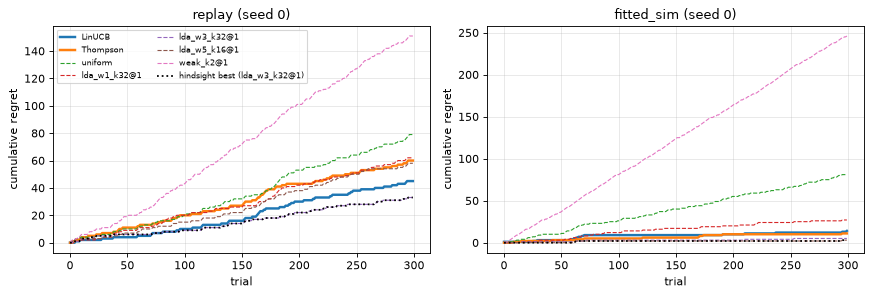

In [6]:
def run_all(env, seed):
    n_a = len(env.actions)
    out = {
        "LinUCB": B.run_bandit(B.LinUCB(n_a, B.CONTEXT_DIM, bc.alpha, seed), env, N_TRIALS, seed),
        "Thompson": B.run_bandit(B.LinearThompson(n_a, B.CONTEXT_DIM, bc.thompson_v, seed), env, N_TRIALS, seed),
    }
    out.update(B.run_baselines(env, N_TRIALS, seed))
    return out

t0 = time.perf_counter()
results = {env.name: {s: run_all(env, s) for s in SEEDS} for env in (replay_env, sim_env)}
print(f"bandit runs in {time.perf_counter() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, env in zip(axes, (replay_env, sim_env)):
    res = results[env.name][SEEDS[0]]
    for name, r in res.items():
        if name.startswith("fixed:") and not name.endswith("@1"):
            continue
        style = dict(lw=2.2) if name in ("LinUCB", "Thompson") else dict(lw=1.0, ls="--")
        ax.plot(r.cum_regret, label=name.replace("fixed:", ""), **style)
    best, hind = B.best_fixed_in_hindsight(res["uniform"])
    ax.plot(hind, "k:", lw=1.6, label=f"hindsight best ({env.actions[best].label})")
    ax.set(title=f"{env.name} (seed {SEEDS[0]})", xlabel="trial", ylabel="cumulative regret")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

In [7]:
rows = []
for env_name, by_seed in results.items():
    for pol in by_seed[SEEDS[0]]:
        finals = [by_seed[s][pol].final_regret for s in SEEDS]
        rows.append({"env": env_name, "policy": pol, "seed0": finals[0],
                     f"mean({len(SEEDS)} seeds)": float(np.mean(finals))})
    hind = [B.best_fixed_in_hindsight(by_seed[s]["uniform"])[1][-1] for s in SEEDS]
    rows.append({"env": env_name, "policy": "best fixed (hindsight)", "seed0": hind[0],
                 f"mean({len(SEEDS)} seeds)": float(np.mean(hind))})
table = pd.DataFrame(rows)
table[table.policy.isin(["LinUCB", "Thompson", "uniform", "best fixed (hindsight)"]) |
      table.policy.str.endswith("@1")].round(1).reset_index(drop=True)

,env,policy,seed0,mean(3 seeds)
0,replay,LinUCB,45.0,46.3
1,replay,Thompson,60.0,56.0
2,replay,uniform,79.0,76.7
3,replay,fixed:lda_w1_k32@1,62.0,60.7
4,replay,fixed:lda_w3_k32@1,33.0,32.7
5,replay,fixed:lda_w5_k16@1,58.0,58.0
6,replay,fixed:weak_k2@1,151.0,149.0
7,replay,best fixed (hindsight),33.0,32.7
8,fitted_sim,LinUCB,14.0,14.7
9,fitted_sim,Thompson,11.0,13.7


## 4 · Which actions do the learners play?

Selection frequency over the 300 trials (seed 0), allowed actions only. In `ReplayEnv` the
gain does not matter, so mass spreads across gain variants of the same arm. In `FittedSimEnv`
the assumed gain rule makes a mid gain better, and the learners should shift towards it.

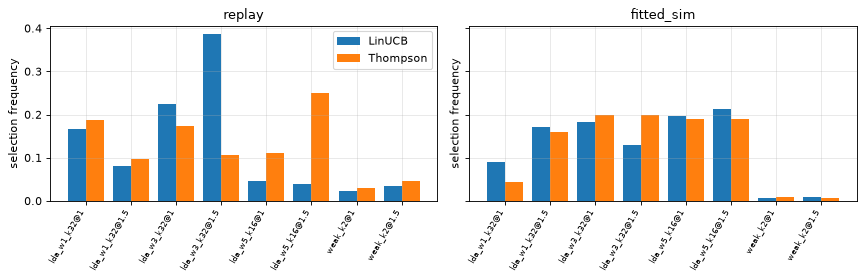

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, env in zip(axes, (replay_env, sim_env)):
    idx = np.flatnonzero(env.mask)
    width = 0.4
    for k, pol in enumerate(("LinUCB", "Thompson")):
        f = results[env.name][SEEDS[0]][pol].selection_frequency()[idx]
        ax.bar(np.arange(len(idx)) + (k - 0.5) * width, f, width, label=pol)
    ax.set_xticks(np.arange(len(idx)), [env.actions[i].label for i in idx], rotation=60, ha="right", fontsize=7)
    ax.set(title=env.name, ylabel="selection frequency")
axes[0].legend(); plt.tight_layout(); plt.show()

## 5 · Safety mask demo

The universe has 15 actions (5 arms x 3 gains); the mask keeps 8. Even a LinUCB with a very
large exploration bonus, which tries every action it is allowed to, never plays a masked one;
a policy forced onto a masked action raises `SafetyViolation`.

In [9]:
mask = replay_env.mask
print("allowed:", int(mask.sum()), "of", len(mask))
print("masked :", [a.label for a, m in zip(replay_env.actions, mask) if not m])
wild = B.run_bandit(B.LinUCB(len(mask), B.CONTEXT_DIM, 100.0, 0), replay_env, N_TRIALS, 0)
print("explorer (alpha=100) played", len(set(wild.chosen)), "distinct actions; any masked:", bool((~mask[wild.chosen]).any()))
try:
    B.run_bandit(B.FixedPolicy(int(np.flatnonzero(~mask)[0])), replay_env, 5, 0)
except B.SafetyViolation as exc:
    print("SafetyViolation:", exc)

allowed: 8 of 15
masked : ['lda_w1_k32@2', 'lda_w3_k32@2', 'lda_w5_k16@2', 'weak_k2@2', 'candidate_unvalidated@1', 'candidate_unvalidated@1.5', 'candidate_unvalidated@2']
explorer (alpha=100) played 8 distinct actions; any masked: False
SafetyViolation: fixed action 2 is masked


## Pitfalls

* **Replay is not closed loop.** Counterfactual rewards assume the user's brain signal does not
  react to the decoder. On a live system the user adapts, and replay regret overstates how
  well offline numbers transfer.
* **Gain is untestable in replay.** Without data recorded under several gains, any gain effect
  comes from the assumed rule in `FittedSimEnv`, not from evidence.
* **Fitted-simulator optimism.** Means are estimated from a few trials per direction and reused
  as truth; no session-to-session drift. Accuracies are higher than in replay.
* **Small samples.** Regret over 300 trials and 3 seeds is a noisy comparison; the ordering of
  close policies (LinUCB vs Thompson) can flip.
* **Logged propensities.** LinUCB is deterministic (propensity 1.0), so its logs cannot support
  inverse-propensity evaluation; use uniform or Thompson logging for that stage.

## Exercise

1. Raise `bc.max_gain` to 2.0 and rerun the fitted-sim section. Which action does the learner
   prefer, and how does the regret change?
2. Set `bc.arms[-1].validated = True` (the candidate) and rebuild the envs. Does it change the
   oracle or the learners' regret?
3. Change `CaltechLikeConfig.n_directions` to 2 and refit. How do arm differences shrink?

In [10]:
import shutil
shutil.rmtree(WORK, ignore_errors=True)
print(f"done in {time.perf_counter() - T0:.1f}s; workspace removed: {not WORK.exists()}")

done in 21.8s; workspace removed: True
